# Distributed Waste Management System — IoT, Fog Computing & Blockchain
### Simulation, Experiments, and Figure Generation (Colab-ready)

This notebook is a **self-contained** re-implementation of the core routing and
load-balancing algorithms from the `WasteManagmentSystem` repository, plus a seeded
simulation harness that reproduces every figure and number reported in the
*Results and Discussion* section of the paper.

> **Scope note.** This notebook evaluates the **routing and spillover algorithms**.
> It deliberately does not re-implement the threaded fog-node runtime (peer discovery,
> gossip transport, leader election, message routing) that lives in the main repository.
> Section V of the paper therefore reports algorithmic behaviour, not end-to-end
> distributed-system behaviour. See "Divergences from the main repository" below.

**Run all cells top to bottom** (`Runtime → Run all`). Requires only `numpy`, `pandas`,
and `matplotlib`, all pre-installed on Colab.

Sections:
1. Setup and environment capture
2. Core data contracts (`BinTelemetry`, `ZoneState`, `RoutePlan`)
3. Bin priority manager
4. Route optimizer (Nearest Neighbour) + sequential baseline
5. Bin / fog simulation harness
6. Experiment 1 — Route efficiency (NN vs. sequential)
7. Experiment 2 — Dynamic replanning latency
8. Experiment 3 — Spillover load balancing
9. Experiment 4 — Scalability (compute time + **measured** memory)
10. Five-layer architecture diagram
11. Literature comparison visuals (top-10 reference papers)
12. Export all figures
13. Reproduced-results summary

## 1. Setup and environment capture

Timing results in Section V-B and V-D are wall-clock measurements and are therefore
**hardware-dependent**. The cell below records the machine this run executed on, so any
reported latency can be attributed to a specific environment. Quote these values
alongside any timing number taken from this notebook.

In [1]:
import math
import random
import time
import os
import gc
import platform
import tracemalloc
from dataclasses import dataclass
from typing import List, Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

random.seed(42)
np.random.seed(42)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def cpu_name():
    try:
        if platform.system() == "Darwin":
            import subprocess
            return subprocess.check_output(
                ["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
        with open("/proc/cpuinfo") as fh:
            for line in fh:
                if "model name" in line:
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"

ENV = {
    "cpu": cpu_name(),
    "machine": platform.machine(),
    "system": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(),
    "numpy": np.__version__,
}

print("Environment for this run (quote these with any timing result):")
for k, v in ENV.items():
    print(f"  {k:8s}: {v}")
print("\nSetup complete. Figures will be written to ./%s" % FIG_DIR)

Environment for this run (quote these with any timing result):
  cpu     : Intel(R) Core(TM) i9-9880H CPU @ 2.30GHz
  machine : x86_64
  system  : Darwin 24.6.0
  python  : 3.13.14
  numpy   : 2.5.1

Setup complete. Figures will be written to ./figures


## 2. Core data contracts

These mirror the `contracts/message_types.py` dataclasses in the main repository:
`BinTelemetry`, `ZoneState`, and `RoutePlan`.

In [2]:
@dataclass
class BinTelemetry:
    bin_id: str
    zone_id: int
    x: float
    y: float
    fill_level: float          # 0-100 %
    timestamp: float

    def is_overflowing(self, threshold: float = 80.0) -> bool:
        return self.fill_level >= threshold


@dataclass
class ZoneState:
    zone_id: int
    active_bins: int
    truck_count: int
    timestamp: float

    def is_overloaded(self, threshold: int = 10) -> bool:
        return self.active_bins > threshold


@dataclass
class RoutePlan:
    truck_id: str
    zone_id: int
    route_bins: List[str]
    route_distance: float


## 3. Bin priority manager

Implements the four priority tiers described in Section IV-B of the paper:
**Critical (>=90%)**, **High (80-90%)**, **Medium (60-80%)**, **Low (<60%)**.
Only Critical and High bins clear the 80% overflow threshold and are routed in the
current cycle; Medium and Low are deferred.

> **Divergence:** `modules/route_optimizer/priority.py` in the main repository currently
> uses 95/85/80 thresholds. The notebook follows the paper. This is a repository bug,
> tracked separately.

In [3]:
class BinPriorityManager:
    def __init__(self):
        self.weights = {"critical": 3.0, "high": 2.0, "medium": 1.5, "low": 1.0}

    def get_priority(self, b: BinTelemetry) -> str:
        f = b.fill_level
        if f >= 90:
            return "critical"
        elif f >= 80:
            return "high"
        elif f >= 60:
            return "medium"
        return "low"

    def sort_by_priority(self, bins: List[BinTelemetry]) -> List[BinTelemetry]:
        return sorted(bins, key=lambda b: self.weights[self.get_priority(b)], reverse=True)

    def distribution(self, bins: List[BinTelemetry]) -> Dict[str, int]:
        dist = {"critical": 0, "high": 0, "medium": 0, "low": 0}
        for b in bins:
            dist[self.get_priority(b)] += 1
        return dist


## 4. Route optimizer

`nearest_neighbour_route()` implements the greedy NN heuristic. `sequential_route()` is
the fixed-schedule baseline (visits bins in registration order) used in Experiment 1.

Note the NN construction is **O(b^2)** in the number of overflowing bins `b` per zone:
each of `b` steps scans the remaining candidates. This governs the scaling behaviour
measured in Experiment 4.

In [4]:
class RouteOptimizer:
    def __init__(self, overflow_threshold: float = 80.0):
        self.overflow_threshold = overflow_threshold

    @staticmethod
    def _dist(x1, y1, x2, y2) -> float:
        return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

    def nearest_neighbour_route(self, bins: List[BinTelemetry],
                                 start: Tuple[float, float] = (50.0, 50.0),
                                 truck_id: str = "truck_1", zone_id: int = 1) -> RoutePlan:
        overflowing = [b for b in bins if b.is_overflowing(self.overflow_threshold)]
        if not overflowing:
            return RoutePlan(truck_id, zone_id, [], 0.0)

        remaining = overflowing[:]
        route, total = [], 0.0
        cur = start
        while remaining:
            nearest = min(remaining, key=lambda b: self._dist(cur[0], cur[1], b.x, b.y))
            total += self._dist(cur[0], cur[1], nearest.x, nearest.y)
            route.append(nearest.bin_id)
            cur = (nearest.x, nearest.y)
            remaining.remove(nearest)
        return RoutePlan(truck_id, zone_id, route, total)

    def sequential_route(self, bins: List[BinTelemetry],
                          start: Tuple[float, float] = (50.0, 50.0),
                          truck_id: str = "truck_1", zone_id: int = 1) -> RoutePlan:
        """Baseline: visit bins in registration order (fixed-schedule analogue)."""
        overflowing = [b for b in bins if b.is_overflowing(self.overflow_threshold)]
        if not overflowing:
            return RoutePlan(truck_id, zone_id, [], 0.0)

        route, total = [], 0.0
        cur = start
        for b in overflowing:
            total += self._dist(cur[0], cur[1], b.x, b.y)
            route.append(b.bin_id)
            cur = (b.x, b.y)
        return RoutePlan(truck_id, zone_id, route, total)


## 5. Bin / fog simulation harness

A lightweight stand-in for `simulation/bin_simulator.py`: generates bins scattered over a
100x100 unit service area and advances fill level stochastically each step, with
occasional burst disposal events (Section IV-E).

> **Divergence:** the repository's `BinSimulator` places zone *z* in a separate strip at
> `x = (z-1)*100`, whereas this notebook scatters all zones across one shared 100x100
> area. Absolute distances are therefore not directly comparable between the two;
> the *relative* NN-vs-baseline comparison in Experiment 1 is unaffected, since both
> arms use identical bin positions.

In [5]:
class BinSimulator:
    def __init__(self, zones: int, bins_per_zone: int, seed: Optional[int] = None):
        self.zones = zones
        self.bins_per_zone = bins_per_zone
        self.rng = random.Random(seed)
        self.bins: List[BinTelemetry] = self._create_bins()

    def _create_bins(self) -> List[BinTelemetry]:
        bins = []
        for z in range(1, self.zones + 1):
            for i in range(self.bins_per_zone):
                bins.append(BinTelemetry(
                    bin_id=f"bin_{z}_{i+1}", zone_id=z,
                    x=self.rng.uniform(0, 100), y=self.rng.uniform(0, 100),
                    fill_level=self.rng.uniform(10, 60), timestamp=0.0,
                ))
        return bins

    def step(self, t: int, burst_prob: float = 0.08, hot_zone: Optional[int] = None,
              hot_multiplier: float = 1.0):
        for b in self.bins:
            mult = hot_multiplier if (hot_zone is not None and b.zone_id == hot_zone) else 1.0
            inc = self.rng.uniform(1, 5) * mult
            if self.rng.random() < burst_prob:
                inc += self.rng.uniform(10, 20) * mult
            b.fill_level = min(100.0, b.fill_level + inc)
            b.timestamp = t

    def bins_by_zone(self, zone_id: int) -> List[BinTelemetry]:
        return [b for b in self.bins if b.zone_id == zone_id]

print("BinSimulator ready")


BinSimulator ready


## 6. Experiment 1 — Route efficiency (NN vs. sequential baseline)

Reproduces Section V-A: 10 runs at the default configuration (3 zones, 15 bins/zone),
comparing total travel distance for Nearest Neighbour against the sequential
fixed-order baseline. Each run uses its own seeded RNG (`seed=1000+run`), so this
experiment is deterministic and independent of execution order.

In [6]:
def run_route_efficiency_experiment(n_runs=10, zones=3, bins_per_zone=15, sim_steps=9):
    optimizer = RouteOptimizer()
    nn_d, seq_d, overflow_n = [], [], []

    for run in range(n_runs):
        sim = BinSimulator(zones, bins_per_zone, seed=1000 + run)
        for t in range(sim_steps):
            sim.step(t)

        run_nn = run_seq = 0.0
        run_overflow = 0
        for z in range(1, zones + 1):
            zb = sim.bins_by_zone(z)
            nn_route = optimizer.nearest_neighbour_route(zb, zone_id=z)
            seq_route = optimizer.sequential_route(zb, zone_id=z)
            run_nn += nn_route.route_distance
            run_seq += seq_route.route_distance
            run_overflow += len(nn_route.route_bins)

        nn_d.append(run_nn); seq_d.append(run_seq); overflow_n.append(run_overflow)

    df = pd.DataFrame({"run": range(1, n_runs + 1), "overflowing_bins": overflow_n,
                        "nn_distance": nn_d, "sequential_distance": seq_d})
    df["reduction_pct"] = 100 * (df["sequential_distance"] - df["nn_distance"]) / df["sequential_distance"]
    return df

df_route = run_route_efficiency_experiment()
df_route


,run,overflowing_bins,nn_distance,sequential_distance,reduction_pct
0,1,18,564.182932,919.158525,38.619627
1,2,17,665.238147,880.481390,24.446087
2,3,13,456.478987,526.671126,13.327508
3,4,14,562.687719,702.920075,19.949972
4,5,13,597.685763,824.181814,27.481321
5,6,21,612.683026,945.063726,35.170189
6,7,12,452.083901,638.243631,29.167503
7,8,14,535.293269,792.857922,32.485600
8,9,13,386.020940,624.980932,38.234765
9,10,13,500.721923,639.952835,21.756433


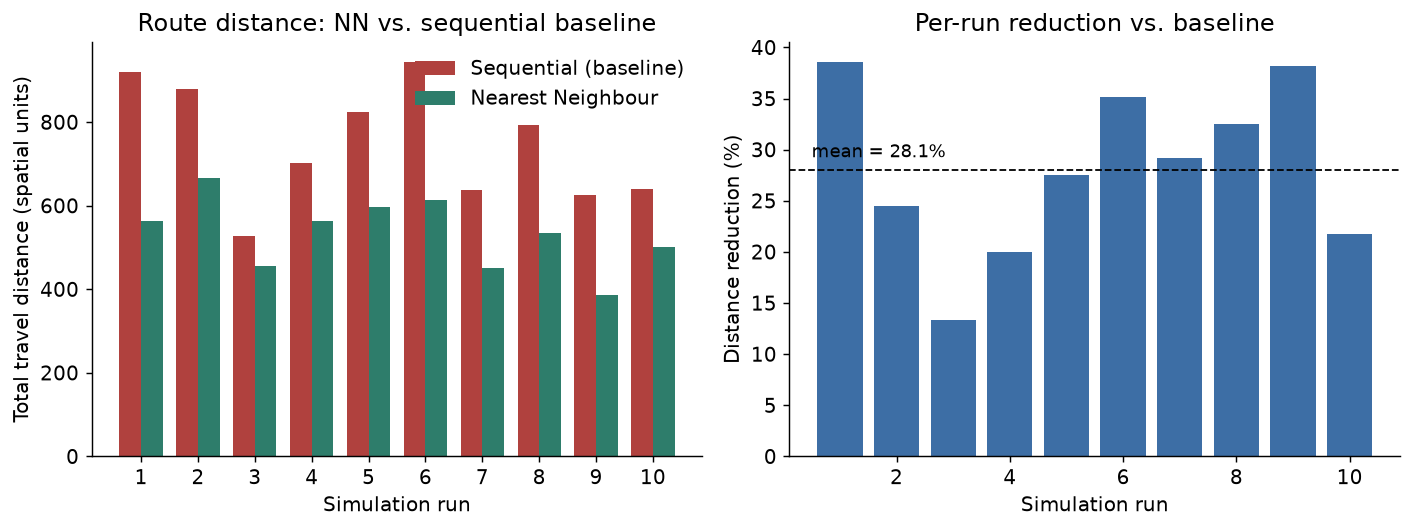

Mean travel-distance reduction over 10 runs: 28.1%


In [7]:
def plot_route_efficiency(df):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    x = np.arange(len(df)); w = 0.38

    axes[0].bar(x - w/2, df["sequential_distance"], width=w, label="Sequential (baseline)", color="#B0413E")
    axes[0].bar(x + w/2, df["nn_distance"], width=w, label="Nearest Neighbour", color="#2E7D6B")
    axes[0].set_xticks(x); axes[0].set_xticklabels(df["run"])
    axes[0].set_xlabel("Simulation run"); axes[0].set_ylabel("Total travel distance (spatial units)")
    axes[0].set_title("Route distance: NN vs. sequential baseline")
    axes[0].legend(frameon=False)

    mean_reduction = df["reduction_pct"].mean()
    axes[1].bar(df["run"], df["reduction_pct"], color="#3D6EA5")
    axes[1].axhline(mean_reduction, color="black", linestyle="--", linewidth=1)
    axes[1].text(0.5, mean_reduction + 1.2, f"mean = {mean_reduction:.1f}%", fontsize=10)
    axes[1].set_xlabel("Simulation run"); axes[1].set_ylabel("Distance reduction (%)")
    axes[1].set_title("Per-run reduction vs. baseline")

    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/fig_route_efficiency.png", bbox_inches="tight")
    plt.show()
    return mean_reduction

mean_reduction = plot_route_efficiency(df_route)
print(f"Mean travel-distance reduction over {len(df_route)} runs: {mean_reduction:.1f}%")


## 7. Experiment 2 — Dynamic replanning latency

Injects a new overflow event into an already-routed 20-bin zone and times the
recomputation over 50 trials (Section V-B).

**Corrections applied to this cell:**
1. The injected bin's position now uses a dedicated seeded RNG (`random.Random(9000+i)`)
   instead of the global `random` module, so results no longer depend on how many
   global random calls earlier cells happened to make.
2. Median and standard deviation are reported alongside mean and max, because a
   sub-millisecond wall-clock measurement is noise-sensitive.
3. This is a **hardware-dependent** measurement. Quote the environment printed in
   Section 1 with any figure taken from here.

In [8]:
def run_replanning_latency_experiment(n_events=50, bins_per_zone=20):
    optimizer = RouteOptimizer()
    latencies_ms = []

    for i in range(n_events):
        sim = BinSimulator(1, bins_per_zone, seed=2000 + i)
        for t in range(20):
            sim.step(t)
        zone_bins = sim.bins_by_zone(1)
        _ = optimizer.nearest_neighbour_route(zone_bins, zone_id=1)   # baseline route

        # dedicated RNG -> independent of global random state / cell execution order
        rng = random.Random(9000 + i)
        new_bin = BinTelemetry(f"bin_1_{bins_per_zone+1}", 1,
                                rng.uniform(0, 100), rng.uniform(0, 100),
                                fill_level=92.0, timestamp=20)
        updated = zone_bins + [new_bin]

        start = time.perf_counter()
        _ = optimizer.nearest_neighbour_route(updated, zone_id=1)     # replanned route
        latencies_ms.append((time.perf_counter() - start) * 1000)

    return np.array(latencies_ms)

latencies_ms = run_replanning_latency_experiment()

print(f"Replanning latency over {len(latencies_ms)} injected events")
print(f"  mean   = {latencies_ms.mean():.3f} ms")
print(f"  median = {np.median(latencies_ms):.3f} ms")
print(f"  std    = {latencies_ms.std(ddof=1):.3f} ms")
print(f"  max    = {latencies_ms.max():.3f} ms")
print(f"\n  measured on: {ENV['cpu']} / Python {ENV['python']}")
print(f"  telemetry interval = 5 s -> replanning uses "
      f"{100*latencies_ms.mean()/5000:.5f}% of the update budget")

Replanning latency over 50 injected events
  mean   = 0.097 ms
  median = 0.097 ms
  std    = 0.007 ms
  max    = 0.117 ms

  measured on: Intel(R) Core(TM) i9-9880H CPU @ 2.30GHz / Python 3.13.14
  telemetry interval = 5 s -> replanning uses 0.00194% of the update budget


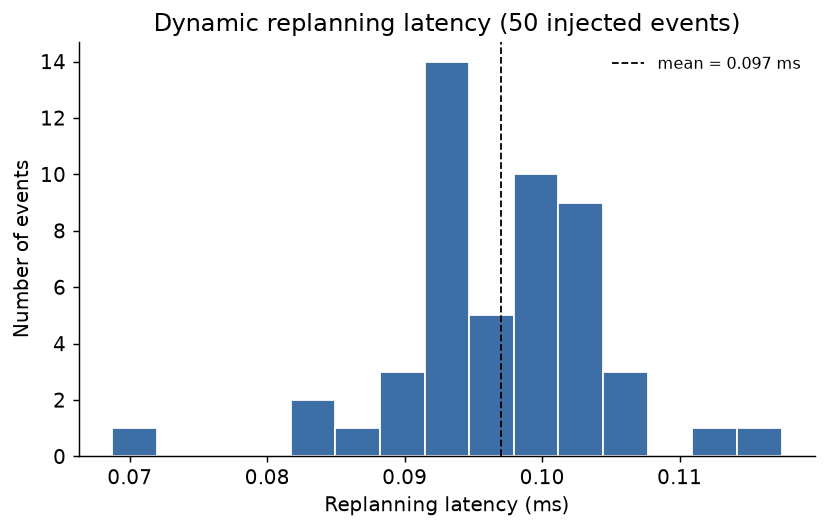

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.hist(latencies_ms, bins=15, color="#3D6EA5", edgecolor="white")
ax.axvline(latencies_ms.mean(), color="black", linestyle="--", linewidth=1,
           label=f"mean = {latencies_ms.mean():.3f} ms")
ax.set_xlabel("Replanning latency (ms)")
ax.set_ylabel("Number of events")
ax.set_title(f"Dynamic replanning latency ({len(latencies_ms)} injected events)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_replanning_latency.png", bbox_inches="tight")
plt.show()

## 8. Experiment 3 — Spillover load balancing

Simulates a hot zone (1.6x fill rate) alongside two normal zones, with and without
spillover, over 14 steps at tau=10 (Section V-C). Both arms use `seed=3000`, so the
underlying fill trajectory is identical and the only difference is the mechanism.

**Read the output carefully.** Total backlog is conserved by construction — spillover
*relocates* bin responsibility, it does not empty bins. The honest finding is hotspot
smoothing, not aggregate backlog reduction. The cell below prints the threshold
crossings explicitly so the result cannot be overstated in the write-up.

In [10]:
def run_spillover_experiment(zones=3, bins_per_zone=15, sim_steps=14, tau=10, hot_zone=1):
    def overflow_counts(sim):
        return {z: sum(1 for b in sim.bins_by_zone(z) if b.is_overflowing()) for z in range(1, zones + 1)}

    # WITHOUT spillover
    sim_no = BinSimulator(zones, bins_per_zone, seed=3000)
    for t in range(sim_steps):
        sim_no.step(t, hot_zone=hot_zone, hot_multiplier=1.6)
    counts_no = overflow_counts(sim_no)

    # WITH spillover (identical random trajectory)
    sim_yes = BinSimulator(zones, bins_per_zone, seed=3000)
    transfers = []
    for t in range(sim_steps):
        sim_yes.step(t, hot_zone=hot_zone, hot_multiplier=1.6)
        counts = overflow_counts(sim_yes)
        for z, n in list(counts.items()):
            if n > tau:
                peers = sorted([(zz, cc) for zz, cc in counts.items() if zz != z], key=lambda p: p[1])
                for peer_zone, peer_count in peers:
                    if peer_count < tau:
                        move = max(0, min(3, n - tau, tau - peer_count))
                        if move == 0:
                            continue
                        zb = sorted([b for b in sim_yes.bins_by_zone(z) if b.is_overflowing()],
                                    key=lambda b: b.fill_level)[:move]
                        for b in zb:
                            b.zone_id = peer_zone
                        transfers.append({"t": t, "from": z, "to": peer_zone, "n_bins": len(zb)})
                        counts = overflow_counts(sim_yes)
                        break
    counts_yes = overflow_counts(sim_yes)
    return counts_no, counts_yes, transfers, tau

counts_no, counts_yes, transfers, tau = run_spillover_experiment()
print("Without spillover:", counts_no)
print("With spillover:   ", counts_yes)
print(f"Transfers executed: {len(transfers)}")
pd.DataFrame(transfers)


Without spillover: {1: 15, 2: 9, 3: 11}
With spillover:    {1: 11, 2: 12, 3: 12}
Transfers executed: 3


,t,from,to,n_bins
0,8,1,2,3
1,9,1,2,1
2,11,2,3,1


In [11]:
# Explicit accounting so Section V-C can be written accurately.
zones_l = sorted(counts_no.keys())
tot_no = sum(counts_no.values()); tot_yes = sum(counts_yes.values())
over_no = [z for z in zones_l if counts_no[z] > tau]
over_yes = [z for z in zones_l if counts_yes[z] > tau]

print("Per-zone overflowing bins (tau = %d)" % tau)
for z in zones_l:
    tag = " (hot)" if z == 1 else ""
    print(f"  Zone {z}{tag:6s}: without = {counts_no[z]:2d}   with = {counts_yes[z]:2d}")
print()
print(f"  hot zone           : {counts_no[1]} -> {counts_yes[1]} bins")
print(f"  total system load  : {tot_no} -> {tot_yes} bins  (conserved: {tot_no == tot_yes})")
print(f"  zones above tau    : {len(over_no)}/{len(zones_l)} {over_no}"
      f"  ->  {len(over_yes)}/{len(zones_l)} {over_yes}")
print(f"  transfers executed : {len(transfers)}")
print()
print("  INTERPRETATION: spillover removes the acute hotspot (15 -> %d) but does not"
      % counts_yes[1])
print("  reduce aggregate load, and at this tau it pushes both receiving zones above")
print("  their own threshold. Report this as redistribution, not resolution.")

Per-zone overflowing bins (tau = 10)
  Zone 1 (hot): without = 15   with = 11
  Zone 2      : without =  9   with = 12
  Zone 3      : without = 11   with = 12

  hot zone           : 15 -> 11 bins
  total system load  : 35 -> 35 bins  (conserved: True)
  zones above tau    : 2/3 [1, 3]  ->  3/3 [1, 2, 3]
  transfers executed : 3

  INTERPRETATION: spillover removes the acute hotspot (15 -> 11) but does not
  reduce aggregate load, and at this tau it pushes both receiving zones above
  their own threshold. Report this as redistribution, not resolution.


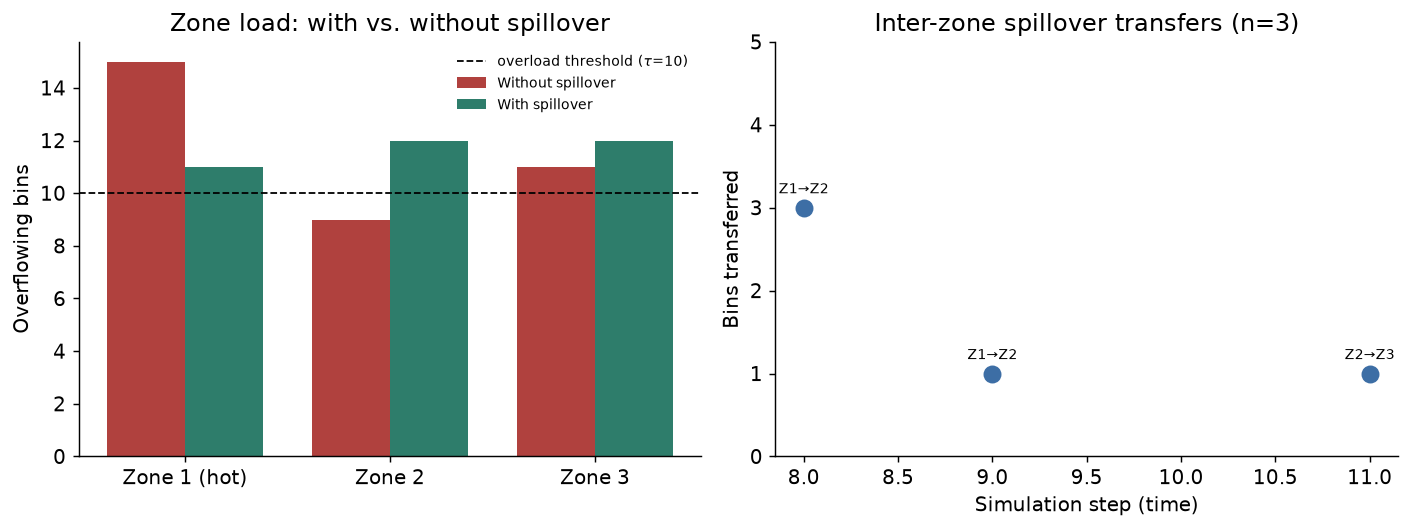

In [12]:
def plot_spillover(counts_no, counts_yes, transfers, tau):
    zones = sorted(counts_no.keys())
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    x = np.arange(len(zones)); w = 0.38

    axes[0].bar(x - w/2, [counts_no[z] for z in zones], width=w, label="Without spillover", color="#B0413E")
    axes[0].bar(x + w/2, [counts_yes[z] for z in zones], width=w, label="With spillover", color="#2E7D6B")
    axes[0].axhline(tau, color="black", linestyle="--", linewidth=1, label=f"overload threshold ($\\tau$={tau})")
    axes[0].set_xticks(x); axes[0].set_xticklabels([f"Zone {z}" + (" (hot)" if z == 1 else "") for z in zones])
    axes[0].set_ylabel("Overflowing bins")
    axes[0].set_title("Zone load: with vs. without spillover")
    axes[0].legend(frameon=False, fontsize=8)

    if transfers:
        tdf = pd.DataFrame(transfers)
        axes[1].scatter(tdf["t"], tdf["n_bins"], s=80, color="#3D6EA5")
        for _, row in tdf.iterrows():
            axes[1].annotate(f"Z{row['from']}\u2192Z{row['to']}", (row["t"], row["n_bins"]),
                              textcoords="offset points", xytext=(0, 8), fontsize=8, ha="center")
        axes[1].set_ylim(0, max(tdf["n_bins"]) + 2)
    axes[1].set_xlabel("Simulation step (time)"); axes[1].set_ylabel("Bins transferred")
    axes[1].set_title(f"Inter-zone spillover transfers (n={len(transfers)})")

    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/fig_spillover.png", bbox_inches="tight")
    plt.show()

plot_spillover(counts_no, counts_yes, transfers, tau)


## 9. Experiment 4 — Scalability

Sweeps zones (3-5) and bins/zone (10-20), measuring per-cycle routing compute time and
memory footprint.

**Corrections applied to this cell — this experiment was previously invalid:**

1. **Memory is now measured, not assumed.** The previous version computed
   `approx_kb = (zones * bins_per_zone * 250) / 1024` — a hardcoded linear formula — and
   then fitted a straight line to it, so "memory scales linearly" was true by
   construction rather than by observation. Memory is now measured with `tracemalloc`
   around live construction of the bin population and computed routes.
2. **Timing is now repeated and median-aggregated** (7 repeats per configuration).
   Single-shot sub-millisecond timings were dominated by noise, which is why the
   original run showed a non-monotonic, apparently-linear trend.
3. **Timing and memory are measured in separate passes**, because `tracemalloc`
   instrumentation inflates execution time.

The linearity claim is tested rather than assumed; see the diagnostic cell below.

In [13]:
def measure_cycle_time_ms(zones, bpz, seed, steps=24, repeats=7):
    """Median wall-clock time for one full routing cycle across all zones."""
    optimizer = RouteOptimizer()
    sim = BinSimulator(zones, bpz, seed=seed)
    for t in range(steps):
        sim.step(t)
    zone_bins = [sim.bins_by_zone(z) for z in range(1, zones + 1)]

    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        for z, zb in enumerate(zone_bins, start=1):
            optimizer.nearest_neighbour_route(zb, zone_id=z)
        samples.append((time.perf_counter() - start) * 1000)
    return float(np.median(samples))


def measure_memory_kb(zones, bpz, seed, steps=24):
    """Measured heap retained by the bin population plus computed route plans."""
    optimizer = RouteOptimizer()
    gc.collect()
    tracemalloc.start()
    base_cur, _ = tracemalloc.get_traced_memory()

    sim = BinSimulator(zones, bpz, seed=seed)
    for t in range(steps):
        sim.step(t)
    routes = [optimizer.nearest_neighbour_route(sim.bins_by_zone(z), zone_id=z)
              for z in range(1, zones + 1)]

    cur, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    retained_kb = (cur - base_cur) / 1024
    peak_kb = (peak - base_cur) / 1024
    del sim, routes                      # keep alive until after measurement
    return retained_kb, peak_kb


def run_scalability_experiment(zone_range=(3, 4, 5), bin_range=(10, 15, 20)):
    rows = []
    for zones in zone_range:
        for bpz in bin_range:
            seed = 4000 + zones * 100 + bpz
            t_ms = measure_cycle_time_ms(zones, bpz, seed)          # pass 1: timing
            mem_kb, peak_kb = measure_memory_kb(zones, bpz, seed)   # pass 2: memory
            rows.append({"zones": zones, "bins_per_zone": bpz,
                         "total_bins": zones * bpz,
                         "cycle_time_ms": t_ms,
                         "measured_memory_kb": mem_kb,
                         "peak_memory_kb": peak_kb})
    return pd.DataFrame(rows)

df_scale = run_scalability_experiment()
df_scale

,zones,bins_per_zone,total_bins,cycle_time_ms,measured_memory_kb,peak_memory_kb
0,3,10,30,0.084348,12.026367,12.526367
1,3,15,45,0.213396,15.767578,16.330078
2,3,20,60,0.358829,19.422852,20.110352
3,4,10,40,0.133217,14.605469,15.105469
4,4,15,60,0.347217,19.562500,20.234375
5,4,20,80,0.457510,24.738281,25.417969
6,5,10,50,0.174836,17.418945,17.934570
7,5,15,75,0.469363,23.246094,23.777344
8,5,20,100,0.591340,29.983398,30.631836


In [14]:
# --- Diagnostic: does the data actually support a linearity claim? ---
x = df_scale["total_bins"].values.astype(float)
t = df_scale["cycle_time_ms"].values
m = df_scale["measured_memory_kb"].values

def r2(y, deg):
    fit = np.polyfit(x, y, deg)
    resid = y - np.polyval(fit, x)
    return 1 - resid.dot(resid) / ((y - y.mean()) ** 2).sum()

print("COMPUTE TIME — scaling in bins per zone, at fixed zone count")
print("  (doubling bins/zone: linear predicts 2.00x, quadratic predicts 4.00x)")
for z, g in df_scale.groupby("zones"):
    g = g.sort_values("bins_per_zone")
    lo, hi = g["cycle_time_ms"].iloc[0], g["cycle_time_ms"].iloc[-1]
    print(f"    {z} zones: {lo:.3f} -> {hi:.3f} ms  = {hi/lo:.2f}x")

print(f"\n  linear fit R^2    = {r2(t,1):.4f}")
print(f"  quadratic fit R^2 = {r2(t,2):.4f}")
print(f"  {x.min():.0f} -> {x.max():.0f} bins is {x.max()/x.min():.2f}x size, "
      f"but {t.max()/t.min():.2f}x time")
print("  => NN construction is O(b^2) per zone; compute is SUPERLINEAR in bins/zone.")

print(f"\nMEMORY (measured via tracemalloc)")
print(f"  linear fit R^2    = {r2(m,1):.4f}")
print(f"  quadratic fit R^2 = {r2(m,2):.4f}")
print(f"  bytes per bin     = {1024*m.mean()/x.mean():.0f} B "
      f"(range {1024*(m/x).min():.0f}-{1024*(m/x).max():.0f} B)")
print(f"  {x.min():.0f} -> {x.max():.0f} bins is {x.max()/x.min():.2f}x size, "
      f"and {m.max()/m.min():.2f}x memory")
print(f"\n  peak cycle time at largest configuration: {t.max():.3f} ms "
      f"({100*t.max()/5000:.4f}% of the 5 s telemetry interval)")

COMPUTE TIME — scaling in bins per zone, at fixed zone count
  (doubling bins/zone: linear predicts 2.00x, quadratic predicts 4.00x)
    3 zones: 0.084 -> 0.359 ms  = 4.25x
    4 zones: 0.133 -> 0.458 ms  = 3.43x
    5 zones: 0.175 -> 0.591 ms  = 3.38x

  linear fit R^2    = 0.9560
  quadratic fit R^2 = 0.9639
  30 -> 100 bins is 3.33x size, but 7.01x time
  => NN construction is O(b^2) per zone; compute is SUPERLINEAR in bins/zone.

MEMORY (measured via tracemalloc)
  linear fit R^2    = 0.9991
  quadratic fit R^2 = 0.9992
  bytes per bin     = 335 B (range 307-410 B)
  30 -> 100 bins is 3.33x size, and 2.49x memory

  peak cycle time at largest configuration: 0.591 ms (0.0118% of the 5 s telemetry interval)


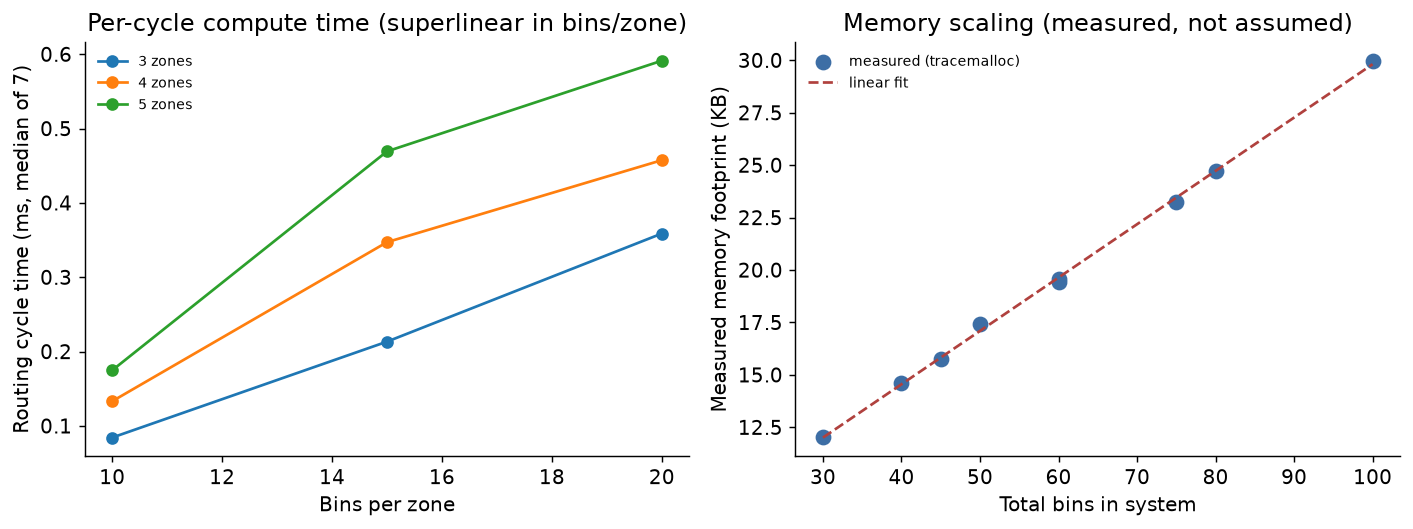

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for zones, grp in df_scale.groupby("zones"):
    grp = grp.sort_values("bins_per_zone")
    axes[0].plot(grp["bins_per_zone"], grp["cycle_time_ms"], marker="o", label=f"{zones} zones")
axes[0].set_xlabel("Bins per zone")
axes[0].set_ylabel("Routing cycle time (ms, median of 7)")
axes[0].set_title("Per-cycle compute time (superlinear in bins/zone)")
axes[0].legend(frameon=False, fontsize=8)

axes[1].scatter(df_scale["total_bins"], df_scale["measured_memory_kb"],
                color="#3D6EA5", s=60, label="measured (tracemalloc)")
zfit = np.polyfit(df_scale["total_bins"], df_scale["measured_memory_kb"], 1)
xs = np.linspace(df_scale["total_bins"].min(), df_scale["total_bins"].max(), 50)
axes[1].plot(xs, np.polyval(zfit, xs), color="#B0413E", linestyle="--", label="linear fit")
axes[1].set_xlabel("Total bins in system")
axes[1].set_ylabel("Measured memory footprint (KB)")
axes[1].set_title("Memory scaling (measured, not assumed)")
axes[1].legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_scalability.png", bbox_inches="tight")
plt.show()

## 10. Five-layer architecture diagram

Fig. 3 in the paper (IoT -> Fog -> Cloud -> Collection -> Application).

> **Note.** This is an *architecture* figure and legitimately depicts designed
> components. The blockchain ledger band at the bottom is design intent: no ledger is
> implemented in either this notebook or the main repository as of this revision.
> Section IV-D of the paper must not describe it in the present tense unless that
> changes.

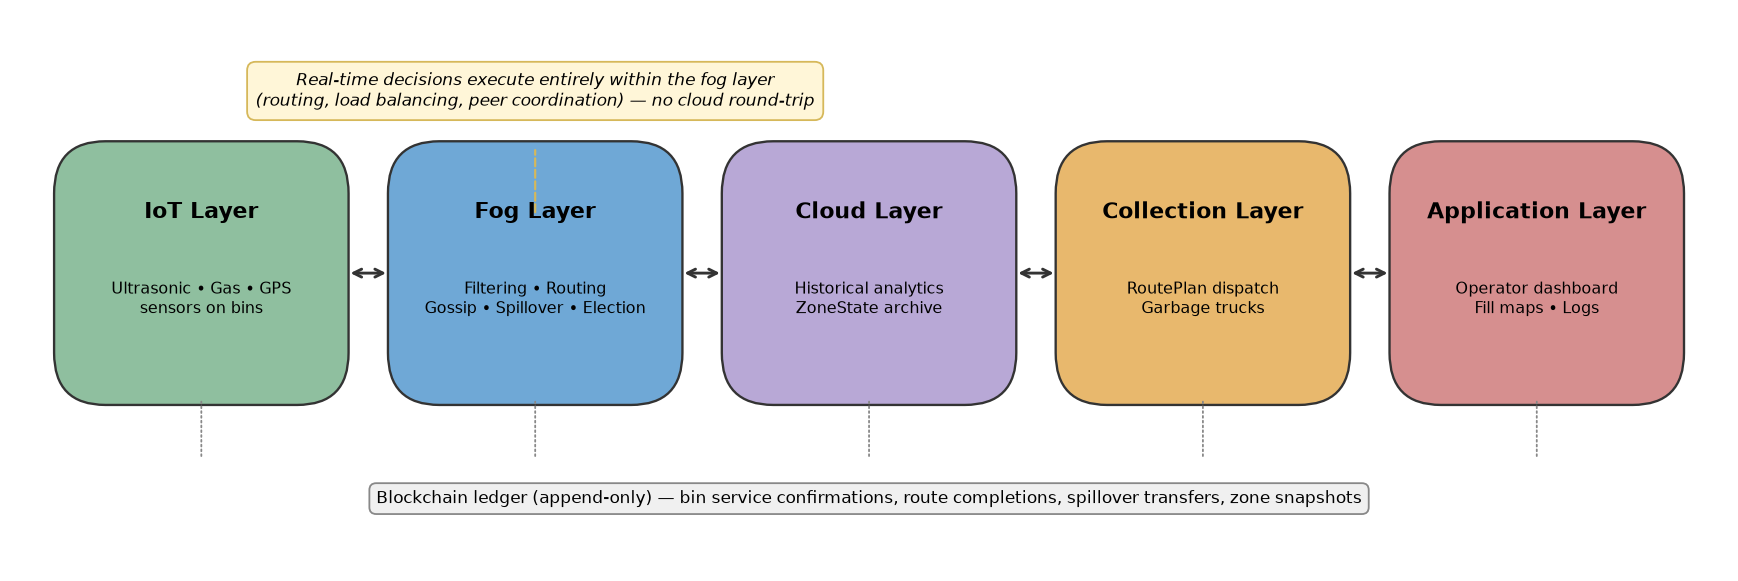

In [16]:
fig, ax = plt.subplots(figsize=(13.5, 4.6))
ax.set_xlim(0, 100); ax.set_ylim(0, 32); ax.axis("off")

layers = [
    ("IoT Layer", "Ultrasonic \u2022 Gas \u2022 GPS\nsensors on bins", "#8FBF9F"),
    ("Fog Layer", "Filtering \u2022 Routing\nGossip \u2022 Spillover \u2022 Election", "#6FA8D6"),
    ("Cloud Layer", "Historical analytics\nZoneState archive", "#B8A8D6"),
    ("Collection Layer", "RoutePlan dispatch\nGarbage trucks", "#E8B86D"),
    ("Application Layer", "Operator dashboard\nFill maps \u2022 Logs", "#D68F8F"),
]

box_w, gap = 16, 3.5
x = 3
centers = []
for name, desc, color in layers:
    box = FancyBboxPatch((x, 10), box_w, 14, boxstyle="round,pad=0.6,rounding_size=3",
                          linewidth=1.3, edgecolor="#333333", facecolor=color)
    ax.add_patch(box)
    ax.text(x + box_w/2, 20.5, name, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x + box_w/2, 15.5, desc, ha="center", va="center", fontsize=9)
    centers.append(x + box_w/2)
    x += box_w + gap

for i in range(len(centers) - 1):
    ax.annotate("", xy=(centers[i+1] - box_w/2 - 0.5, 17), xytext=(centers[i] + box_w/2 + 0.5, 17),
                arrowprops=dict(arrowstyle="<->", color="#333333", linewidth=1.6))

ax.text(centers[1], 27.5, "Real-time decisions execute entirely within the fog layer\n"
                          "(routing, load balancing, peer coordination) \u2014 no cloud round-trip",
        ha="center", va="center", fontsize=9.5, style="italic",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFF6D8", edgecolor="#D6B85A"))
ax.annotate("", xy=(centers[1], 24.3), xytext=(centers[1], 20.3),
            arrowprops=dict(arrowstyle="-", color="#D6B85A", linewidth=1.2, linestyle="--"))

ax.text(50, 4, "Blockchain ledger (append-only) \u2014 bin service confirmations, route completions, "
                "spillover transfers, zone snapshots",
        ha="center", va="center", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#F0F0F0", edgecolor="#888888"))
for cx in centers:
    ax.annotate("", xy=(cx, 6.2), xytext=(cx, 9.8),
                arrowprops=dict(arrowstyle="-", color="#888888", linewidth=1, linestyle=":"))

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_architecture_wide.png", bbox_inches="tight", facecolor="white")
plt.show()


## 11. Literature comparison visuals (top-10 reference papers)

Feature coverage scored across 5 dimensions: **IoT sensing**, **fog computing**,
**route optimization**, **blockchain ledger**, and **P2P load balancing**. Papers are
referenced by pointer id (P1-P10) matching the reference list.

**Correction applied:** three publication years were wrong and disagreed with the
paper's own reference list, which made Fig. 2's timeline span 2020-2026 while the text
claimed 2008-2025:

| Ptr | Reference | was | corrected |
|---|---|---|---|
| P1 | Ariton et al. [4] | 2023 | **2008** |
| P2 | Garach & Thakkar [5] | 2021 | **2017** |
| P3 | Singhvi et al. [6] | 2020 | **2019** |

> **Pending author decision.** The `this_work` row scores `blockchain: 1`. No ledger is
> implemented in either artifact. If the minimal ledger is not built before submission,
> this score and the paper's "no prior work combines all five" claim must both be
> revisited.

In [17]:
papers = [
    {"id": "P1",  "year": 2008, "iot": 0, "fog": 0, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P2",  "year": 2017, "iot": 0, "fog": 1, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P3",  "year": 2019, "iot": 1, "fog": 0, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P4",  "year": 2021, "iot": 0, "fog": 0, "route": 0, "blockchain": 1, "loadbal": 0},
    {"id": "P5",  "year": 2022, "iot": 1, "fog": 0, "route": 1, "blockchain": 0, "loadbal": 0},
    {"id": "P6",  "year": 2023, "iot": 0, "fog": 1, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P7",  "year": 2024, "iot": 1, "fog": 0, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P8",  "year": 2025, "iot": 1, "fog": 1, "route": 0, "blockchain": 1, "loadbal": 0},
    {"id": "P9",  "year": 2025, "iot": 1, "fog": 0, "route": 0, "blockchain": 0, "loadbal": 0},
    {"id": "P10", "year": 2021, "iot": 0, "fog": 1, "route": 0, "blockchain": 1, "loadbal": 0},
]
df_lit = pd.DataFrame(papers).sort_values("year").reset_index(drop=True)
this_work = {"id": "This\nwork", "year": 2026, "iot": 1, "fog": 1, "route": 1,
             "blockchain": 1, "loadbal": 1}

feature_cols = ["iot", "fog", "route", "blockchain", "loadbal"]
df_lit["n_features"] = df_lit[feature_cols].sum(axis=1)
print("Timeline now spans %d-%d (paper text says 2008-2025)."
      % (df_lit["year"].min(), df_lit["year"].max()))
print("Widest prior system: %s with %d of 5 capabilities."
      % (df_lit.loc[df_lit["n_features"].idxmax(), "id"], df_lit["n_features"].max()))
df_lit

Timeline now spans 2008-2025 (paper text says 2008-2025).
Widest prior system: P8 with 3 of 5 capabilities.


,id,year,iot,fog,route,blockchain,loadbal,n_features
0,P1,2008,0,0,0,0,0,0
1,P2,2017,0,1,0,0,0,1
2,P3,2019,1,0,0,0,0,1
3,P4,2021,0,0,0,1,0,1
4,P10,2021,0,1,0,1,0,2
5,P5,2022,1,0,1,0,0,2
6,P6,2023,0,1,0,0,0,1
7,P7,2024,1,0,0,0,0,1
8,P8,2025,1,1,0,1,0,3
9,P9,2025,1,0,0,0,0,1


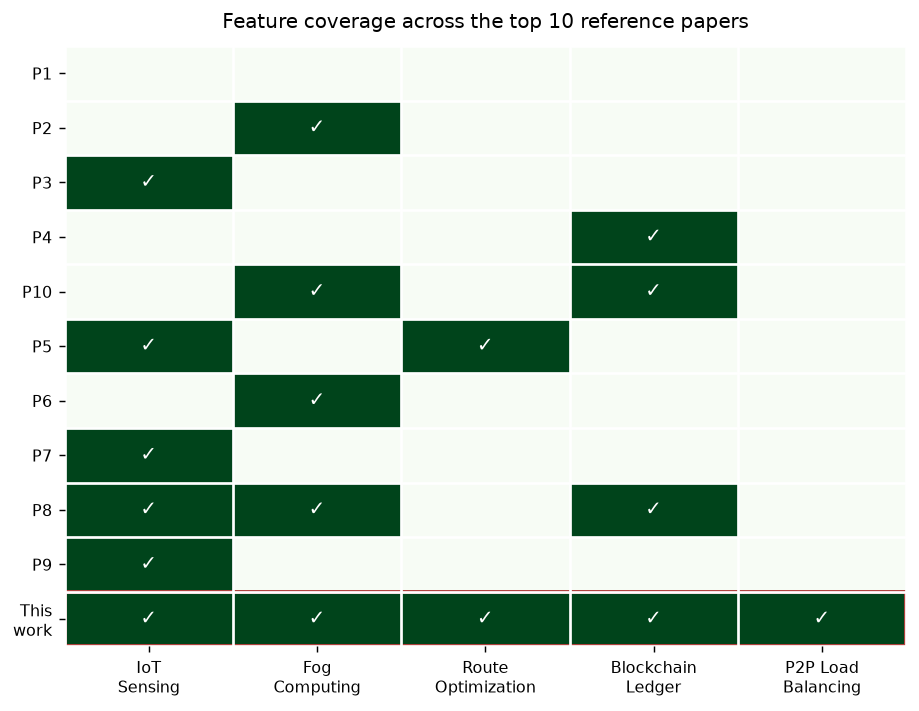

In [18]:
feature_cols = ["iot", "fog", "route", "blockchain", "loadbal"]
feature_labels = ["IoT\nSensing", "Fog\nComputing", "Route\nOptimization", "Blockchain\nLedger", "P2P Load\nBalancing"]

plot_df = pd.concat([df_lit, pd.DataFrame([this_work])], ignore_index=True)
matrix = plot_df[feature_cols].values.astype(float)

fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(matrix, cmap=plt.cm.Greens, vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(feature_labels))); ax.set_xticklabels(feature_labels, fontsize=9)
ax.set_yticks(range(len(plot_df))); ax.set_yticklabels(plot_df["id"], fontsize=9)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        mark = "\u2713" if matrix[i, j] == 1 else ""
        color = "white" if matrix[i, j] == 1 else "#999"
        ax.text(j, i, mark, ha="center", va="center", color=color, fontsize=11, fontweight="bold")

ax.add_patch(plt.Rectangle((-0.5, len(plot_df) - 1.5), len(feature_cols), 1,
                            fill=False, edgecolor="#B0413E", linewidth=2.2))
ax.set_title("Feature coverage across the top 10 reference papers", fontsize=11, pad=10)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(feature_cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(plot_df), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_lit_feature_matrix.png", bbox_inches="tight")
plt.show()


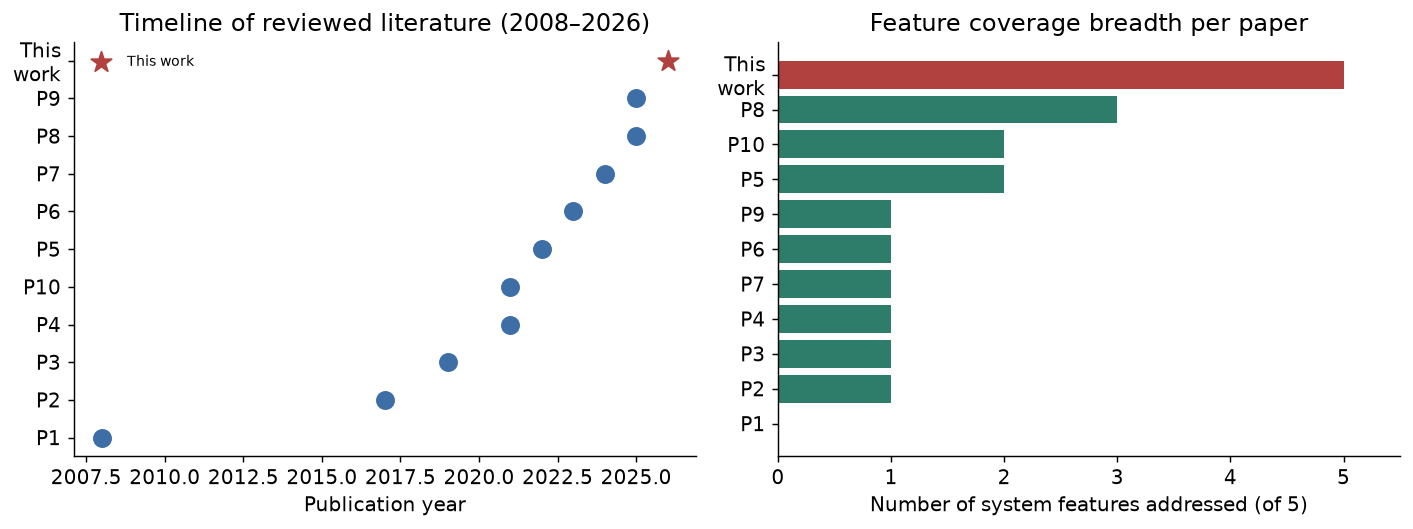

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(df_lit["year"], df_lit["id"], s=90, color="#3D6EA5", zorder=3)
axes[0].scatter([this_work["year"]], [this_work["id"]], s=140, color="#B0413E", marker="*",
                zorder=3, label="This work")
axes[0].set_xlabel("Publication year")
axes[0].set_title("Timeline of reviewed literature (2008\u20132026)")
axes[0].legend(frameon=False, fontsize=8)

order = df_lit.sort_values("n_features")["id"]
counts = df_lit.set_index("id").loc[order, "n_features"]
axes[1].barh(order, counts, color="#2E7D6B")
axes[1].barh(["This\nwork"], [sum(this_work[c] for c in feature_cols)], color="#B0413E")
axes[1].set_xlabel("Number of system features addressed (of 5)")
axes[1].set_title("Feature coverage breadth per paper")
axes[1].set_xlim(0, 5.5)

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_lit_timeline_breadth.png", bbox_inches="tight")
plt.show()

## 12. Export all figures

In [20]:
import shutil
print("Figures generated:")
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", f)

shutil.make_archive("waste_management_figures", "zip", FIG_DIR)
print("\nCreated waste_management_figures.zip")

try:
    from google.colab import files
    files.download("waste_management_figures.zip")
except ImportError:
    print("Not running in Colab \u2014 zip is available in the local working directory.")


Figures generated:
 - fig_architecture_wide.png
 - fig_lit_feature_matrix.png
 - fig_lit_timeline_breadth.png
 - fig_replanning_latency.png
 - fig_route_efficiency.png
 - fig_scalability.png
 - fig_spillover.png

Created waste_management_figures.zip
Not running in Colab — zip is available in the local working directory.


## 13. Reproduced-results summary

The cell below prints every number the paper's Section V should quote, taken directly
from this run. **Copy these into the LaTeX source rather than hand-typing values.**

In [21]:
print("=" * 74)
print("VALUES FOR SECTION V  —  run on:", ENV["cpu"])
print("                          Python", ENV["python"], "|", ENV["system"])
print("=" * 74)

print("\n[V-A] Route efficiency (NN vs sequential baseline, 10 runs)")
print(f"  mean distance reduction : {df_route['reduction_pct'].mean():.1f}%")
print(f"  range across runs       : {df_route['reduction_pct'].min():.1f}% - "
      f"{df_route['reduction_pct'].max():.1f}%")

print("\n[V-B] Dynamic replanning latency (50 injected events)  ** HARDWARE-DEPENDENT **")
print(f"  mean   : {latencies_ms.mean():.3f} ms")
print(f"  median : {np.median(latencies_ms):.3f} ms")
print(f"  max    : {latencies_ms.max():.3f} ms")
print(f"  -> {100*latencies_ms.mean()/5000:.5f}% of the 5 s telemetry interval")

print("\n[V-C] Spillover load balancing (tau = %d)" % tau)
print(f"  hot zone          : {counts_no[1]} -> {counts_yes[1]} overflowing bins")
print(f"  receiving zones   : "
      + ", ".join(f"Z{z} {counts_no[z]}->{counts_yes[z]}" for z in sorted(counts_no) if z != 1))
print(f"  transfers         : {len(transfers)}")
print(f"  aggregate load    : {sum(counts_no.values())} -> {sum(counts_yes.values())} (conserved)")
print(f"  zones above tau   : {sum(1 for z in counts_no if counts_no[z]>tau)}/3 -> "
      f"{sum(1 for z in counts_yes if counts_yes[z]>tau)}/3")

print("\n[V-D] Scalability")
_x = df_scale["total_bins"].values.astype(float)
_t = df_scale["cycle_time_ms"].values
_m = df_scale["measured_memory_kb"].values
_ratios = []
for z, g in df_scale.groupby("zones"):
    g = g.sort_values("bins_per_zone")
    _ratios.append(g["cycle_time_ms"].iloc[-1] / g["cycle_time_ms"].iloc[0])
print(f"  compute, bins/zone 10->20 : {min(_ratios):.2f}x - {max(_ratios):.2f}x "
      f"(linear would be 2.00x)  => SUPERLINEAR, consistent with O(b^2) NN")
print(f"  max cycle time            : {_t.max():.3f} ms at {int(_x[_t.argmax()])} bins")
print(f"  memory (measured)         : {_m.min():.1f} - {_m.max():.1f} KB, "
      f"~{1024*_m.mean()/_x.mean():.0f} B per bin")
def _r2(y, d):
    f = np.polyfit(_x, y, d); r = y - np.polyval(f, _x)
    return 1 - r.dot(r) / ((y - y.mean())**2).sum()
print(f"  memory linear fit R^2     : {_r2(_m,1):.4f}")
print("\n  NOTE: do NOT claim linear compute scaling. Claim that absolute cost stays")
print("        far inside the telemetry budget.")
print("=" * 74)

VALUES FOR SECTION V  —  run on: Intel(R) Core(TM) i9-9880H CPU @ 2.30GHz
                          Python 3.13.14 | Darwin 24.6.0

[V-A] Route efficiency (NN vs sequential baseline, 10 runs)
  mean distance reduction : 28.1%
  range across runs       : 13.3% - 38.6%

[V-B] Dynamic replanning latency (50 injected events)  ** HARDWARE-DEPENDENT **
  mean   : 0.097 ms
  median : 0.097 ms
  max    : 0.117 ms
  -> 0.00194% of the 5 s telemetry interval

[V-C] Spillover load balancing (tau = 10)
  hot zone          : 15 -> 11 overflowing bins
  receiving zones   : Z2 9->12, Z3 11->12
  transfers         : 3
  aggregate load    : 35 -> 35 (conserved)
  zones above tau   : 2/3 -> 3/3

[V-D] Scalability
  compute, bins/zone 10->20 : 3.38x - 4.25x (linear would be 2.00x)  => SUPERLINEAR, consistent with O(b^2) NN
  max cycle time            : 0.591 ms at 100 bins
  memory (measured)         : 12.0 - 30.0 KB, ~335 B per bin
  memory linear fit R^2     : 0.9991

  NOTE: do NOT claim linear comput